Author:  
Manuel Eugenio Morocho Cayamcela, PhD

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [ ]:
# 1. Dimensiones del conjunto de datos
print("DIMENSIONES DEL DATASET")
print(df.shape)

# 2. Tipos de datos
print("\nTIPOS DE DATOS")
print(df.dtypes)

# 3. Valores faltantes
print("\nVALORES FALTANTES")
print(df.isnull().sum())

# 4. Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe())

DIMENSIONES DEL DATASET
(891, 12)

TIPOS DE DATOS
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

VALORES FALTANTES
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

ESTADÍSTICAS DESCRIPTIVAS


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

El conjunto de datos contiene 891 pasajeros y 12 variables. Se identificaron variables numéricas y categóricas que permiten analizar las características de los pasajeros del Titanic.

Las estadísticas descriptivas muestran una edad promedio de 29,70 años y una tasa general de supervivencia del 38,38 %.

Se encontraron 177 valores faltantes en la variable edad y 2 en el puerto de embarque. Es necesario revisar también los valores faltantes de las demás columnas.

Para comprobar las hipótesis relacionadas con el sexo y la clase del pasajero, no es necesario eliminar los registros con edades faltantes, ya que las variables Sex, Pclass y Survived están completas.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

SUPERVIVENCIA POR SEXO


,count,sum,mean,Porcentaje
Sex,,,,
female,314,233,0.742038,74.203822
male,577,109,0.188908,18.890815


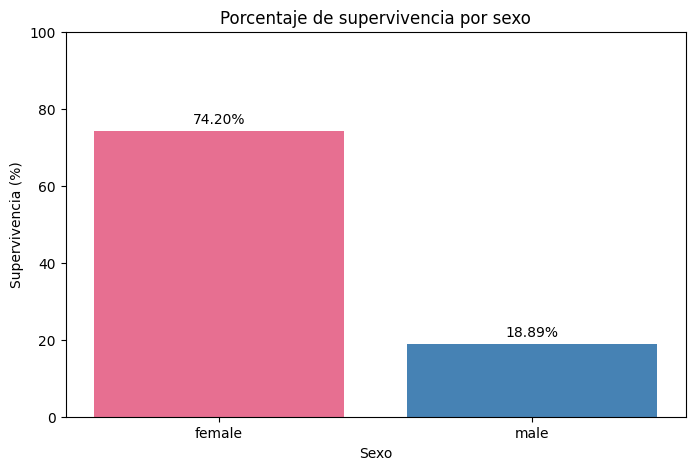

In [3]:
import matplotlib.pyplot as plt

# Calcular supervivencia por sexo
supervivencia_sexo = (
    df.groupby("Sex")["Survived"]
    .agg(["count", "sum", "mean"])
)

supervivencia_sexo["Porcentaje"] = (
    supervivencia_sexo["mean"] * 100
)

print("SUPERVIVENCIA POR SEXO")
display(supervivencia_sexo)

# Crear gráfico
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    supervivencia_sexo.index,
    supervivencia_sexo["Porcentaje"],
    color=["#E76F91", "#4682B4"]
)

ax.set_title("Porcentaje de supervivencia por sexo")
ax.set_xlabel("Sexo")
ax.set_ylabel("Supervivencia (%)")
ax.set_ylim(0, 100)

for barra in barras:
    valor = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 2,
        f"{valor:.2f}%",
        ha="center"
    )

plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

### Interpretación de la hipótesis 1

Los resultados muestran que las mujeres tuvieron una tasa de supervivencia del 74,20 %, mientras que los hombres alcanzaron únicamente el 18,89 %.

De las 314 mujeres registradas, sobrevivieron 233, mientras que de los 577 hombres sobrevivieron 109.

La diferencia de 55,31 puntos porcentuales evidencia una relación importante entre el sexo del pasajero y su supervivencia.

Por lo tanto, los resultados respaldan la hipótesis 1, ya que las mujeres presentaron una probabilidad de supervivencia considerablemente mayor que los hombres en el conjunto de datos analizado.

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

SUPERVIVENCIA POR CLASE


,count,sum,mean,Porcentaje
Pclass,,,,
1,216,136,0.629630,62.962963
2,184,87,0.472826,47.282609
3,491,119,0.242363,24.236253


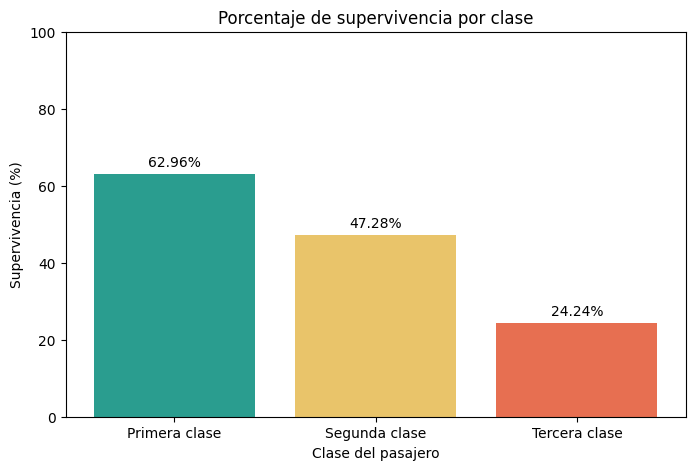

In [4]:
# Calcular supervivencia por clase
supervivencia_clase = (
    df.groupby("Pclass")["Survived"]
    .agg(["count", "sum", "mean"])
)

supervivencia_clase["Porcentaje"] = (
    supervivencia_clase["mean"] * 100
)

print("SUPERVIVENCIA POR CLASE")
display(supervivencia_clase)

# Crear gráfico
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    ["Primera clase", "Segunda clase", "Tercera clase"],
    supervivencia_clase["Porcentaje"],
    color=["#2A9D8F", "#E9C46A", "#E76F51"]
)

ax.set_title("Porcentaje de supervivencia por clase")
ax.set_xlabel("Clase del pasajero")
ax.set_ylabel("Supervivencia (%)")
ax.set_ylim(0, 100)

for barra in barras:
    valor = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 2,
        f"{valor:.2f}%",
        ha="center"
    )

plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

### Interpretación de la hipótesis 2

Los resultados muestran que los pasajeros de primera clase tuvieron una tasa de supervivencia del 62,96 %, seguidos por los de segunda clase con el 47,28 % y los de tercera clase con el 24,24 %.

De los 216 pasajeros de primera clase sobrevivieron 136, mientras que en segunda clase sobrevivieron 87 de 184 y en tercera clase 119 de 491.

Se observa una diferencia de 38,73 puntos porcentuales entre la primera y la tercera clase, lo que evidencia una relación entre la clase del pasajero y su supervivencia.

Por lo tanto, los resultados respaldan la hipótesis 2, ya que los pasajeros de primera clase presentaron una tasa de supervivencia considerablemente superior a la de las otras clases.

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>